In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)

df_original = pd.read_csv(r"D:\tasks\House_Rent_Dataset.csv")
print('Dataset shape:', df_original.shape)
display(df_original.head())


Dataset shape: (4746, 12)


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [2]:
display(df_original.info())
display(df_original.describe(include='all').T)
print('Missing values:')
display(df_original.isna().sum().sort_values(ascending=False))
print('Duplicate rows:', df_original.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   str    
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   str    
 5   Area Type          4739 non-null   str    
 6   Area Locality      4746 non-null   str    
 7   City               4746 non-null   str    
 8   Furnishing Status  4746 non-null   str    
 9   Tenant Preferred   4746 non-null   str    
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   str    
dtypes: float64(3), int64(1), str(8)
memory usage: 445.1 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Posted On,4746,81,7/6/2022,311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BHK,4746.0,NaN,NaN,NaN,2.08386,0.832256,1.0,2.0,2.0,3.0,6.0
Rent,4741.0,NaN,NaN,NaN,35023.395908,78142.139158,1200.0,10000.0,16000.0,33000.0,3500000.0
Size,4738.0,NaN,NaN,NaN,967.936049,634.562635,10.0,550.0,850.0,1200.0,8000.0
Floor,4746,480,1 out of 2,379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area Type,4739,3,Super Area,2442,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area Locality,4746,2235,Bandra West,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,4746,6,Mumbai,972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Furnishing Status,4746,3,Semi-Furnished,2251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenant Preferred,4746,3,Bachelors/Family,3444,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:


Size                 8
Area Type            7
Rent                 5
Bathroom             4
Posted On            0
BHK                  0
Area Locality        0
Floor                0
City                 0
Furnishing Status    0
Tenant Preferred     0
Point of Contact     0
dtype: int64

Duplicate rows: 0


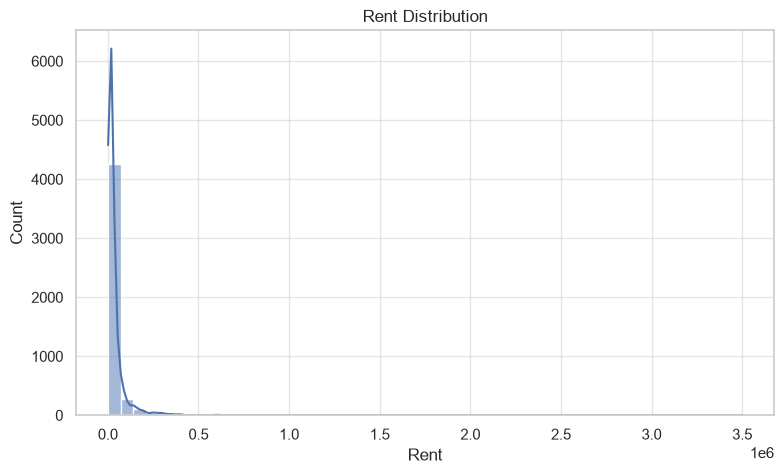

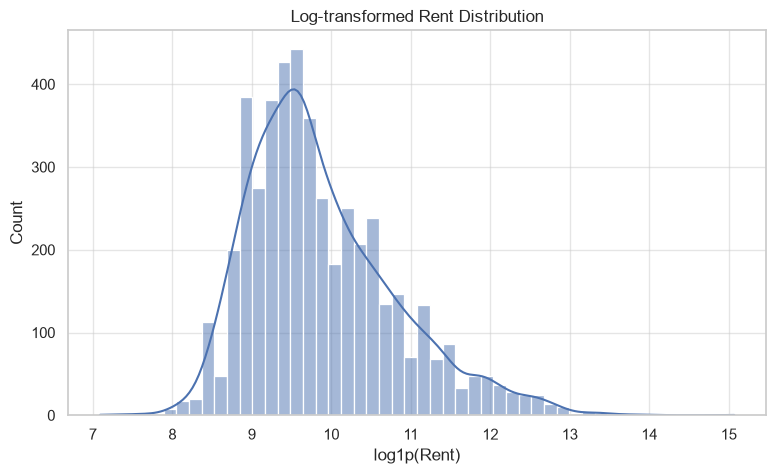

In [3]:
plt.figure(figsize=(9, 5))
sns.histplot(df_original['Rent'], bins=50, kde=True)
plt.title('Rent Distribution')
plt.xlabel('Rent')
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(np.log1p(df_original['Rent'].dropna()), bins=50, kde=True)
plt.title('Log-transformed Rent Distribution')
plt.xlabel('log1p(Rent)')
plt.show()


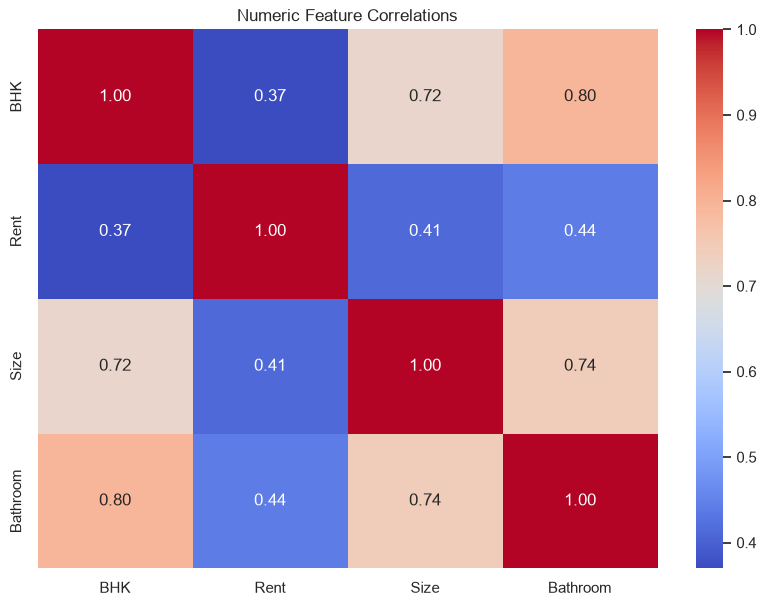

In [4]:
numeric_cols = df_original.select_dtypes(include=np.number).columns
plt.figure(figsize=(10, 7))
sns.heatmap(df_original[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Numeric Feature Correlations')
plt.show()


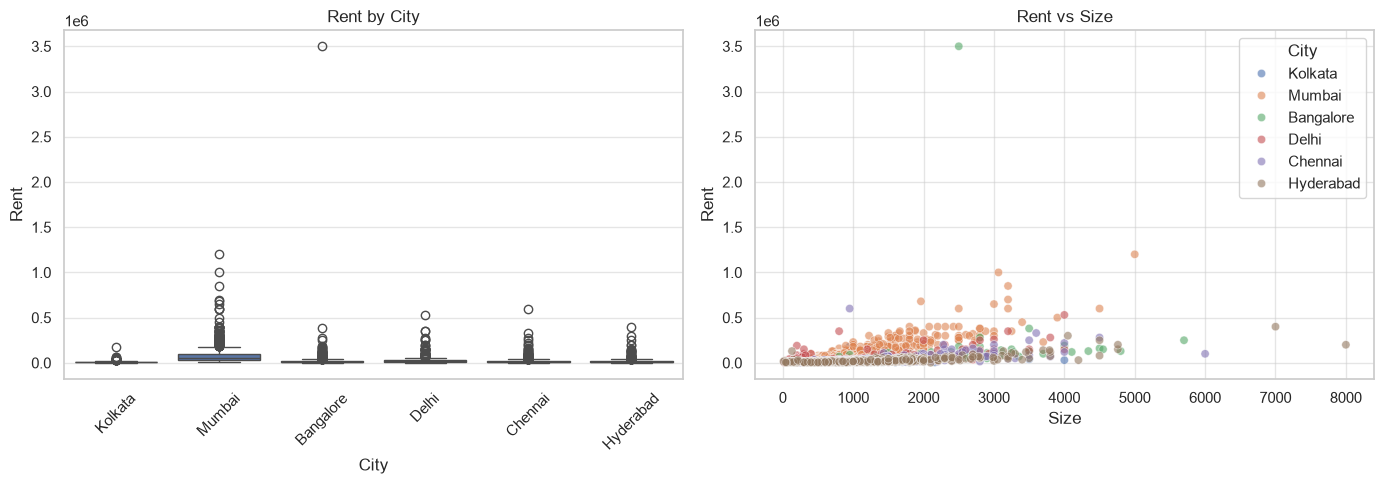

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_original, x='City', y='Rent', ax=axes[0])
axes[0].set_title('Rent by City')
axes[0].tick_params(axis='x', rotation=45)
sns.scatterplot(data=df_original, x='Size', y='Rent', hue='City', alpha=.6, ax=axes[1])
axes[1].set_title('Rent vs Size')
plt.tight_layout()
plt.show()


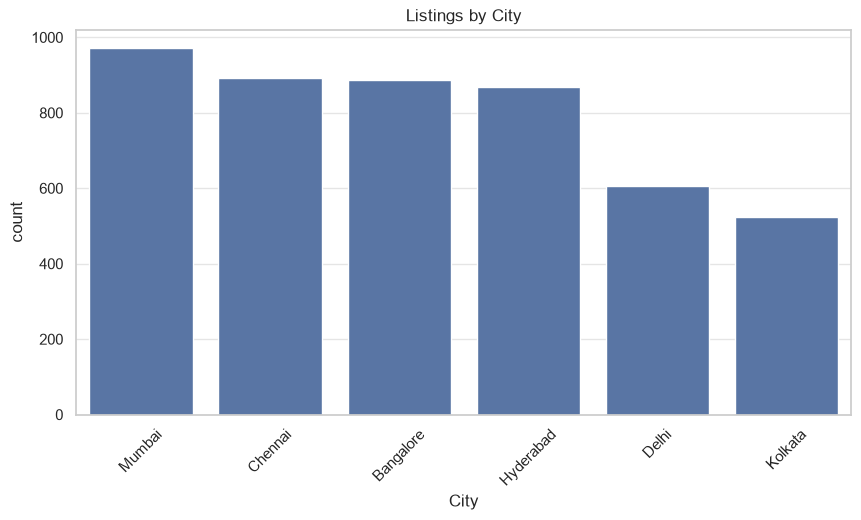

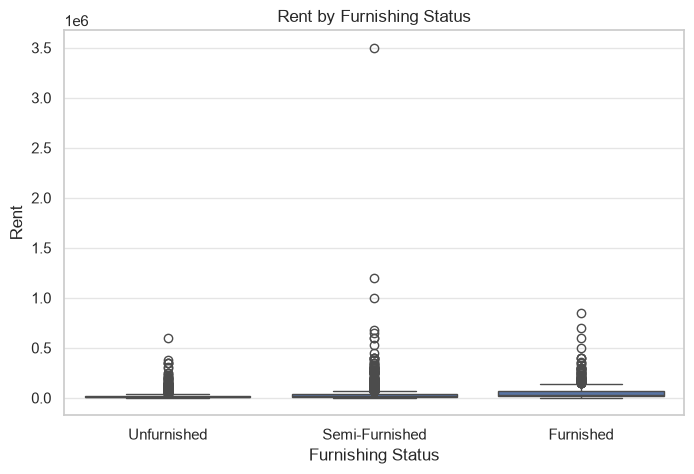

In [6]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df_original, x='City', order=df_original['City'].value_counts().index)
plt.title('Listings by City')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_original, x='Furnishing Status', y='Rent')
plt.title('Rent by Furnishing Status')
plt.show()


In [7]:
df = df_original.copy()
df = df.drop_duplicates()
df = df.dropna(subset=['Rent'])
df = df[df['Rent'] > 0].copy()

df['Posted On'] = pd.to_datetime(df['Posted On'], errors='coerce')
df['Posted_Month'] = df['Posted On'].dt.month
df['Posted_Day'] = df['Posted On'].dt.day
df['Posted_Weekday'] = df['Posted On'].dt.dayofweek

def parse_floor(value):
    value = str(value).strip().lower()
    parts = value.split(' out of ')
    if len(parts) == 2:
        floor_part, total_part = parts
        total = pd.to_numeric(total_part, errors='coerce')
        if floor_part in ['ground', 'gf']:
            floor = 0
        elif floor_part in ['upper']:
            floor = pd.to_numeric(total_part, errors='coerce')
        else:
            floor = pd.to_numeric(floor_part, errors='coerce')
        return pd.Series([floor, total])
    if value in ['ground', 'gf']:
        return pd.Series([0, np.nan])
    return pd.Series([pd.to_numeric(value, errors='coerce'), np.nan])

df[['Floor_Number', 'Total_Floors']] = df['Floor'].apply(parse_floor)
df = df.drop(columns=['Posted On', 'Floor', 'Point of Contact'])

print('Shape after cleaning:', df.shape)
display(df.head())


Shape after cleaning: (4741, 14)


,BHK,Rent,Size,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Posted_Month,Posted_Day,Posted_Weekday,Floor_Number,Total_Floors
0,2,10000.0,1100.0,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,5,18,2,0.0,2.0
1,2,20000.0,NaN,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,5,13,4,1.0,3.0
2,2,17000.0,1000.0,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,5,16,0,1.0,3.0
3,2,10000.0,NaN,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,7,4,0,1.0,2.0
4,2,7500.0,850.0,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,5,9,0,1.0,2.0


In [8]:
TARGET = 'Rent'
X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)


Numeric features: ['BHK', 'Size', 'Bathroom', 'Posted_Month', 'Posted_Day', 'Posted_Weekday', 'Floor_Number', 'Total_Floors']
Categorical features: ['Area Type', 'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred']


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)


Train shape: (3792, 13)
Test shape: (949, 13)


In [10]:
models = {
    'Dummy (Median)': DummyRegressor(strategy='median'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Random Forest': RandomForestRegressor(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
    'Extra Trees': ExtraTreesRegressor(n_estimators=250, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE)
}

results = []
pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    results.append({
        'Model': name,
        'CV MAE': -cv_scores.mean(),
        'CV MAE Std': cv_scores.std()
    })

results_df = pd.DataFrame(results).sort_values('CV MAE')
display(results_df)


,Model,CV MAE,CV MAE Std
4,Extra Trees,10430.792520,716.093419
3,Random Forest,10622.753628,827.531276
5,Gradient Boosting,11597.577590,524.267887
2,Ridge,17930.794625,345.126548
1,Linear Regression,18684.965001,1284.630886
0,Dummy (Median),23739.825299,1335.218464


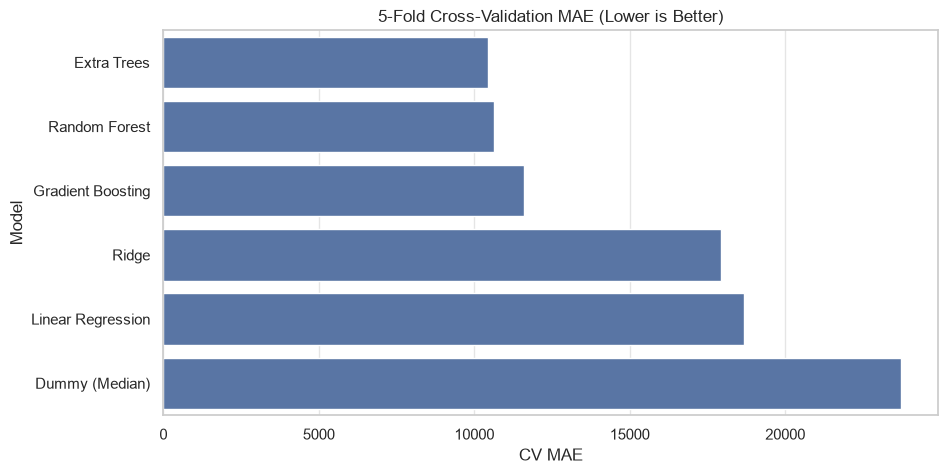

In [11]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='CV MAE', y='Model')
plt.title('5-Fold Cross-Validation MAE (Lower is Better)')
plt.show()


In [12]:
best_model_name = results_df.iloc[0]['Model']
best_pipeline = pipelines[best_model_name]
y_pred = best_pipeline.predict(X_test)

test_metrics = pd.DataFrame([{
    'Model': best_model_name,
    'MAE': mean_absolute_error(y_test, y_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
    'R2': r2_score(y_test, y_pred)
}])
display(test_metrics)
print('Selected model:', best_model_name)


,Model,MAE,RMSE,R2
0,Extra Trees,15649.963562,118916.297907,0.201829


Selected model: Extra Trees


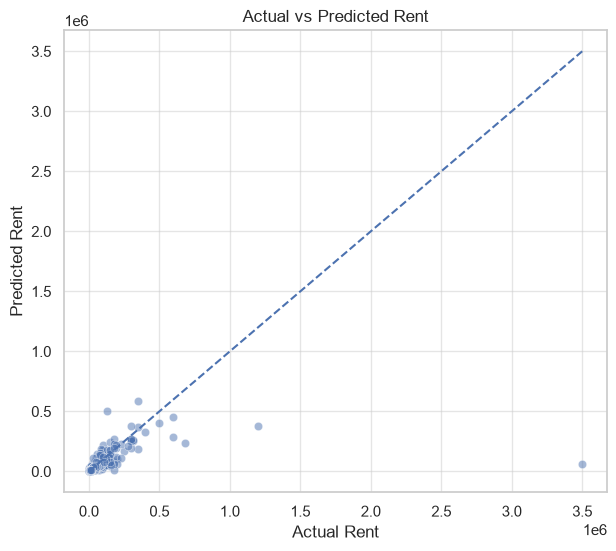

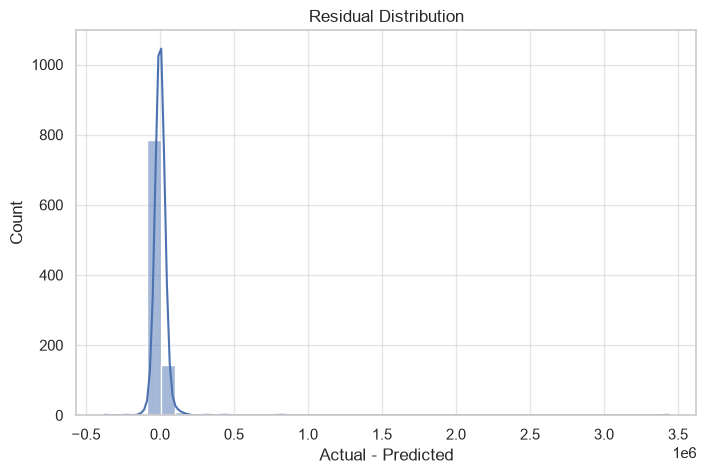

In [13]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=.5)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')
plt.xlabel('Actual Rent')
plt.ylabel('Predicted Rent')
plt.title('Actual vs Predicted Rent')
plt.show()

residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.title('Residual Distribution')
plt.xlabel('Actual - Predicted')
plt.show()


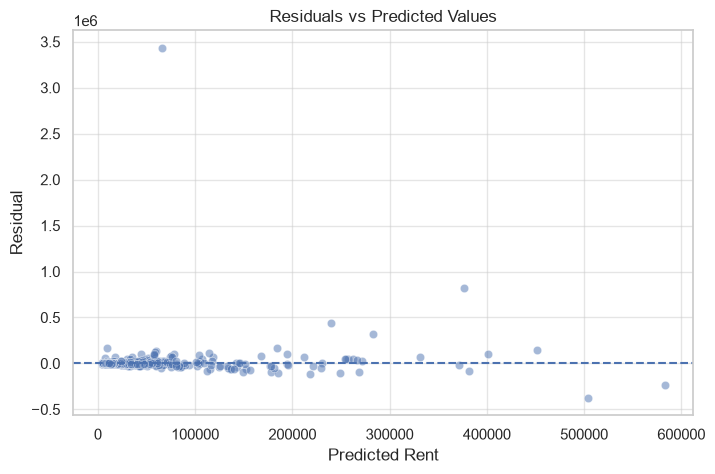

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=.5)
plt.axhline(0, linestyle='--')
plt.xlabel('Predicted Rent')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted Values')
plt.show()


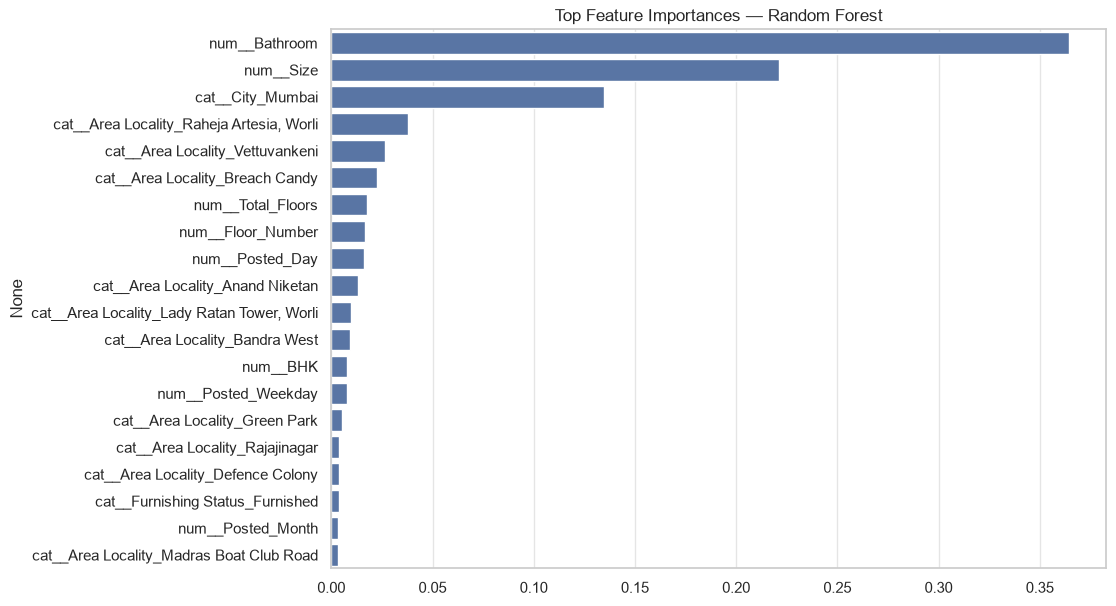

,Importance
num__Bathroom,0.364618
num__Size,0.221057
cat__City_Mumbai,0.134923
"cat__Area Locality_Raheja Artesia, Worli",0.038034
cat__Area Locality_Vettuvankeni,0.026496
cat__Area Locality_Breach Candy,0.022638
num__Total_Floors,0.017673
num__Floor_Number,0.016448
num__Posted_Day,0.016200
cat__Area Locality_Anand Niketan,0.013209


In [15]:
tree_model_names = ['Random Forest', 'Extra Trees', 'Gradient Boosting']
importance_model_name = next((n for n in tree_model_names if n in pipelines), None)

if importance_model_name:
    pipe = pipelines[importance_model_name]
    model = pipe.named_steps['model']
    feature_names = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False).head(20)
    plt.figure(figsize=(10, 7))
    sns.barplot(x=importances.values, y=importances.index)
    plt.title(f'Top Feature Importances — {importance_model_name}')
    plt.show()
    display(importances.to_frame('Importance'))


In [16]:
prediction_sample = pd.DataFrame({
    'Actual Rent': y_test.iloc[:20].values,
    'Predicted Rent': y_pred[:20]
})
display(prediction_sample)


,Actual Rent,Predicted Rent
0,16000.0,20700.000
1,20000.0,12640.000
2,250000.0,167332.000
3,8500.0,7785.200
4,9500.0,7413.384
5,5500.0,14194.000
6,22500.0,31052.000
7,55000.0,59910.000
8,400000.0,331040.000
9,6250.0,9669.600
